# EMQA_L1_profile_annual

**Annual seasonality: load, hydro, solar and the Romanian price by month**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_profile_annual/EMQA_L1_profile_annual.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Monthly profile of Romanian load, hydro and solar generation (mean GW) and of the Romanian day-ahead price relative to its annual mean (median over the years): spring is cheap when water and sun meet mild demand.

**Data:** monthly means 2016-2025. **Source:** energy-charts.info (Fraunhofer ISE); exchange prices (OPCOM, IBEX, HUPX, EPEX SPOT) via ENTSO-E.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Romanian generation by source, daily mean MW (CET day)
G = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]
# daily base prices (mean of all market time units of the CET/CEST day), EUR/MWh
P = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]

data cut-off: 2026-10-31


## Computation

In [4]:
fy1 = Y - 1                                                    # last full year
mm = G.loc['2016':str(fy1)].resample('MS').mean()
pm = P['RO'].loc['2016':str(fy1)].resample('MS').mean()
ratio = pm / pm.groupby(pm.index.year).transform('mean')        # monthly price / mean of that year
mprof = pd.DataFrame({'load': mm['load'].groupby(mm.index.month).mean() / 1000,
                      'hydro': (mm['hydro_run_of_river'] + mm['hydro_water_reservoir']).groupby(mm.index.month).mean() / 1000,
                      'solar': mm['solar'].groupby(mm.index.month).mean() / 1000,
                      'price_ratio': ratio.groupby(ratio.index.month).median()})
show('season.annual.price_max_m', 'month with the highest relative price', int(mprof['price_ratio'].idxmax()))
show('season.annual.price_max', 'highest relative price', fl(mprof['price_ratio'].max(), 2))
show('season.annual.price_min_m', 'month with the lowest relative price', int(mprof['price_ratio'].idxmin()))
show('season.annual.price_min', 'lowest relative price', fl(mprof['price_ratio'].min(), 2))
show('season.annual.load_max_m', 'month with the highest load', int(mprof['load'].idxmax()))

month with the highest relative price = 1   [season.annual.price_max_m]
highest relative price = 1.26   [season.annual.price_max]
month with the lowest relative price = 4   [season.annual.price_min_m]
lowest relative price = 0.72   [season.annual.price_min]
month with the highest load = 1   [season.annual.load_max_m]


## Chart

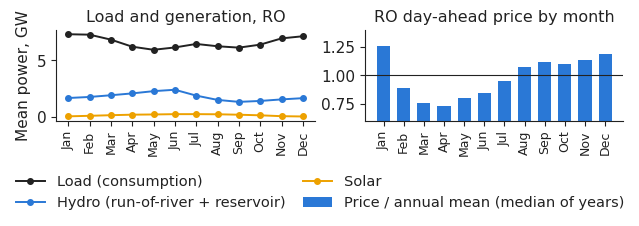

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.3))
for c, col, lab in [('load', '#222222', 'Load (consumption)'), ('hydro', PAL['RO'], 'Hydro (run-of-river + reservoir)'),
                    ('solar', PAL['BG'], 'Solar')]:
    axs[0].plot(range(1, 13), mprof[c], color=col, marker='o', ms=4, label=lab)
axs[0].set_ylabel('Mean power, GW')
axs[0].set_title('Load and generation, RO')
axs[1].bar(range(1, 13), mprof['price_ratio'], color=PAL['RO'], width=0.65, label='Price / annual mean (median of years)')
axs[1].axhline(1.0, color='#222222', lw=0.8)
axs[1].set_ylim(0.6, 1.4)
axs[1].set_title('RO day-ahead price by month')
for ax in axs:
    month_ticks(ax)
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.22, 1, 1))
plt.savefig('profile_annual.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()